# Этап 2.2. Источники данных и аналитический портрет

**Тема:** анализ данных об энергопотреблении для выявления сезонных и поведенческих паттернов использования энергии.

**Объект исследования:** формирование спроса и цены на рынке электроэнергии на сутки вперёд, ценовая зона Германия–Люксембург (DE-LU), 2019–2025 гг., шаг — час.

| № | Источник | Тип по п.3 | Что даёт |
|:-:|:--|:--|:--|
| 1 | Open Power System Data | 3.1 реляционный (SQLite) | цена, нагрузка, ветер и солнце, 2015–2020 |
| 2 | ENTSO-E Transparency Platform | 3.2 XML | цена, нагрузка, генерация |
| 3 | Eurostat `nrg_cb_pem` | 3.2 XML (SDMX) | производство по видам топлива и странам, месяц |
| 4 | Energy-Charts API | 3.3 JSON | цена, нагрузка, генерация, 2019–2025 |
| 5 | Open-Meteo Archive API | 3.3 JSON | погода |
| 6 | Nager.Date API | 3.3 JSON | праздники |
| 7 | Google News RSS | 3.4 текст | новостной фон |

Ответы API сохраняются в `data/raw/`: повторный запуск берёт данные с диска. Время этапов замеряется через `time.perf_counter()`.

## 0. Подготовка

In [2]:
import json, os, sqlite3, time
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

RAW = Path('data/raw')
START, END = '2019-01-01', '2025-12-31'
YEARS = range(2019, 2026)
CITIES = {'Berlin': (52.52, 13.41), 'Hamburg': (53.55, 9.99), 'Munich': (48.14, 11.58),
          'Frankfurt': (50.11, 8.68), 'Cologne': (50.94, 6.96)}

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.prop_cycle': plt.cycler(color=COLORS),
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})

In [ ]:
def get(url, cache_file, params=None):
    path = RAW / cache_file
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        for attempt in range(5):
            r = requests.get(url, params=params, timeout=300, headers={'User-Agent': 'Mozilla/5.0'})
            if r.status_code != 429:
                break
            time.sleep(15)  # API ограничивает частоту запросов
        r.raise_for_status()
        path.write_bytes(r.content)
    return path.read_bytes()


def overview(df):
    '''Тип, доля пропусков и число уникальных значений по каждому столбцу.'''
    return pd.DataFrame({'тип': df.dtypes,
                         'пропуски, %': df.isna().mean().mul(100).round(2),
                         'уникальных': df.nunique()})


timings = []

def log_time(source, stage, t0):
    timings.append({'источник': source, 'этап': stage, 'секунд': time.perf_counter() - t0})

## 1. Open Power System Data — реляционный набор (SQLite)

https://data.open-power-system-data.org/time_series/ — база SQLite (226 МБ) с таблицами для шага 15, 30 и 60 минут. Столбцы названы по схеме `<регион>_<переменная>_<атрибут>`, например `DE_LU_price_day_ahead`.

In [3]:
t0 = time.perf_counter()
get('https://data.open-power-system-data.org/time_series/2020-10-06/time_series.sqlite', 'opsd/time_series.sqlite')
con = sqlite3.connect(RAW / 'opsd/time_series.sqlite')
log_time('1 OPSD', 'загрузка', t0)

pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)

,name
0,time_series_15min_singleindex
1,time_series_30min_singleindex
2,time_series_60min_singleindex


Агрегация на стороне СУБД — среднемесячные значения по Германии:

In [4]:
t0 = time.perf_counter()
opsd_monthly = pd.read_sql('''
    SELECT substr(utc_timestamp, 1, 7)          AS month,
           AVG(DE_LU_price_day_ahead)           AS price,
           AVG(DE_load_actual_entsoe_transparency) AS load_mw,
           AVG(DE_wind_generation_actual)       AS wind_mw,
           AVG(DE_solar_generation_actual)      AS solar_mw
    FROM time_series_60min_singleindex
    WHERE DE_LU_price_day_ahead IS NOT NULL
    GROUP BY month
''', con)
log_time('1 OPSD', 'SQL-агрегация', t0)
opsd_monthly.round(1).tail()

,month,price,load_mw,wind_mw,solar_mw
20,2020-05,17.6,48669.1,10224.5,8328.7
21,2020-06,26.2,49645.4,8857.1,7942.8
22,2020-07,30.1,51126.6,9395.0,8446.7
23,2020-08,34.9,50805.0,9047.2,7309.9
24,2020-09,43.7,52655.2,8834.2,6441.5


In [5]:
t0 = time.perf_counter()
columns = pd.read_sql('PRAGMA table_info(time_series_60min_singleindex)', con)['name']
de_cols = [c for c in columns if c.startswith('DE_')]
opsd = pd.read_sql(f"SELECT utc_timestamp, {', '.join(de_cols)} FROM time_series_60min_singleindex",
                   con, parse_dates=['utc_timestamp'])
log_time('1 OPSD', 'чтение', t0)

print(opsd.shape, opsd.utc_timestamp.min(), '—', opsd.utc_timestamp.max())
opsd[['utc_timestamp', 'DE_LU_price_day_ahead', 'DE_load_actual_entsoe_transparency',
      'DE_solar_generation_actual', 'DE_wind_generation_actual']].dropna().head()

(50401, 42) 2014-12-31 23:00:00+00:00 — 2020-09-30 23:00:00+00:00


,utc_timestamp,DE_LU_price_day_ahead,DE_load_actual_entsoe_transparency,DE_solar_generation_actual,DE_wind_generation_actual
32856,2018-09-30 23:00:00+00:00,56.10,42126.0,0.0,6042.0
32857,2018-10-01 00:00:00+00:00,51.41,41500.0,0.0,6021.0
32858,2018-10-01 01:00:00+00:00,47.38,42353.0,0.0,6342.0
32859,2018-10-01 02:00:00+00:00,47.59,43802.0,0.0,7144.0
32860,2018-10-01 03:00:00+00:00,51.61,48065.0,0.0,7855.0


Три категориальных аспекта зашиты в названия столбцов: регион, переменная и атрибут. Разберём их:

In [6]:
aspects = pd.Series(de_cols).str.extract(
    r'^(DE(?:_LU|_50hertz|_amprion|_tennet|_transnetbw)?)_(load|price|solar|wind_onshore|wind_offshore|wind)_(.+)$')
aspects.columns = ['region', 'variable', 'attribute']
pd.crosstab(aspects.region, aspects.variable)

variable,load,price,solar,wind,wind_offshore,wind_onshore
region,,,,,,
DE,2,0,3,3,3,3
DE_50hertz,2,0,1,1,1,1
DE_LU,2,1,1,1,1,1
DE_amprion,2,0,1,0,0,1
DE_tennet,2,0,1,1,1,1
DE_transnetbw,2,0,1,0,0,1


In [7]:
overview(opsd).sort_values('пропуски, %', ascending=False).head(10)

,тип,"пропуски, %",уникальных
DE_LU_load_forecast_entsoe_transparency,float64,66.95,13191
DE_LU_load_actual_entsoe_transparency,float64,65.23,14013
DE_LU_solar_generation_actual,float64,65.20,7299
DE_LU_price_day_ahead,float64,65.20,6055
DE_LU_wind_onshore_generation_actual,float64,65.19,12589
DE_LU_wind_generation_actual,float64,65.19,13419
DE_LU_wind_offshore_generation_actual,float64,65.19,5868
DE_solar_profile,float64,13.30,5595
DE_wind_profile,float64,13.25,8240
DE_wind_offshore_profile,float64,13.25,12884


**Вывод.** В почасовой таблице 50 401 строка (01.2015 – 09.2020) и 41 столбец по Германии. Категориальные аспекты: 6 регионов (страна, зона DE_LU и 4 зоны операторов сетей), 6 переменных (нагрузка, цена, солнце, ветер на суше и на море) и атрибуты (факт, прогноз, мощность, профиль). Около 65% пропусков в столбцах `DE_LU_*` — это не ошибки: зона DE-LU существует только с 01.10.2018. Источник используется как ретроспектива и для сверки с Energy-Charts на интервале 10.2018–09.2020.

## 2. ENTSO-E Transparency Platform — XML

API `https://web-api.tp.entsoe.eu/api` требует бесплатный токен: регистрация на transparency.entsoe.eu → запрос роли Web API Consumer. Токен задаётся переменной окружения `ENTSOE_TOKEN`.

Структура ответа (документ A44 — цены):

```
Publication_MarketDocument
 └─ TimeSeries   — зона, бизнес-тип, тип генерации (psrType), тип кривой
     └─ Period   — начало интервала, шаг (PT15M / PT60M)
         └─ Point — position, price.amount (или quantity для нагрузки и генерации)
```

При `curveType = A03` повторяющиеся значения не передаются; такие пропуски заполняются протягиванием на этапе подготовки (п.4).

In [8]:
def parse_entsoe(xml_bytes):
    rows = []
    for ts in ET.fromstring(xml_bytes).findall('.//{*}TimeSeries'):
        zone = ts.findtext('{*}in_Domain.mRID') or ts.findtext('{*}outBiddingZone_Domain.mRID')
        psr_type = ts.findtext('.//{*}psrType')
        for period in ts.findall('{*}Period'):
            start = pd.Timestamp(period.findtext('{*}timeInterval/{*}start'))
            step = pd.Timedelta(minutes=int(period.findtext('{*}resolution')[2:-1]))  # 'PT15M' -> 15
            for point in period.findall('{*}Point'):
                value = point.findtext('{*}price.amount') or point.findtext('{*}quantity')
                rows.append({'zone': zone, 'psr_type': psr_type,
                             'ts': start + (int(point.findtext('{*}position')) - 1) * step,
                             'value': float(value)})
    return pd.DataFrame(rows)

In [9]:
TOKEN = os.getenv('ENTSOE_TOKEN')

if TOKEN:
    t0 = time.perf_counter()
    entsoe = pd.concat([
        parse_entsoe(get('https://web-api.tp.entsoe.eu/api', f'entsoe/A44_{y}.xml', {
            'securityToken': TOKEN, 'documentType': 'A44',
            'in_Domain': '10Y1001A1001A82H', 'out_Domain': '10Y1001A1001A82H',
            'periodStart': f'{y - 1}12312300', 'periodEnd': f'{y}12312300'}))
        for y in YEARS])
    log_time('2 ENTSO-E', 'загрузка и разбор', t0)
else:
    # Токена нет — проверяем парсер на примере структуры из документации (значения условные)
    sample = b'''<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:3">
      <TimeSeries>
        <in_Domain.mRID>10Y1001A1001A82H</in_Domain.mRID>
        <curveType>A03</curveType>
        <Period>
          <timeInterval><start>2025-10-01T22:00Z</start><end>2025-10-01T23:00Z</end></timeInterval>
          <resolution>PT15M</resolution>
          <Point><position>1</position><price.amount>101.5</price.amount></Point>
          <Point><position>3</position><price.amount>95.2</price.amount></Point>
        </Period>
      </TimeSeries>
    </Publication_MarketDocument>'''
    entsoe = parse_entsoe(sample)

entsoe.head()

,zone,psr_type,ts,value
0,10Y1001A1001A82H,None,2025-10-01 22:00:00+00:00,101.5
1,10Y1001A1001A82H,None,2025-10-01 22:30:00+00:00,95.2


## 3. Eurostat `nrg_cb_pem` — XML (SDMX)

Помесячное производство электроэнергии по видам топлива, без ключа. Структура: `Series` (ключ: freq, siec, unit, geo) → `Obs` (период, значение).

Коды видов топлива (SIEC): `TOTAL` — всего, `CF` — ископаемое топливо, `N9000` — атом, `RA100` — гидро, `RA300` — ветер, `RA400` — солнце.

In [10]:
t0 = time.perf_counter()
xml_bytes = get('https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/nrg_cb_pem/'
                'M.TOTAL+CF+N9000+RA100+RA300+RA400.GWH.DE+FR+PL+AT+NL+DK',
                'eurostat/nrg_cb_pem.xml', {'startPeriod': '2019-01', 'endPeriod': '2025-12'})
log_time('3 Eurostat', 'загрузка', t0)

t0 = time.perf_counter()
rows = []
for series in ET.fromstring(xml_bytes).findall('.//{*}Series'):
    key = {v.get('id'): v.get('value') for v in series.findall('{*}SeriesKey/{*}Value')}
    for obs in series.findall('{*}Obs'):
        rows.append({**key,
                     'period': obs.find('{*}ObsDimension').get('value'),
                     'gwh': float(obs.find('{*}ObsValue').get('value'))})
eurostat = pd.DataFrame(rows)
eurostat['period'] = pd.to_datetime(eurostat.period)
log_time('3 Eurostat', 'разбор', t0)

print(eurostat.shape)
eurostat.head()

(3024, 6)


,geo,siec,unit,freq,period,gwh
0,AT,CF,GWH,M,2019-01-01,2321.566
1,AT,CF,GWH,M,2019-02-01,1925.473
2,AT,CF,GWH,M,2019-03-01,1333.531
3,AT,CF,GWH,M,2019-04-01,1161.877
4,AT,CF,GWH,M,2019-05-01,711.234


In [11]:
mix = eurostat.pivot_table(index=['geo', 'period'], columns='siec', values='gwh')
mix['res_share'] = (mix.RA100 + mix.RA300 + mix.RA400) / mix.TOTAL
mix['fossil_share'] = mix.CF / mix.TOTAL
mix.groupby('geo')[['TOTAL', 'res_share', 'fossil_share']].mean().round(2).sort_values('res_share')

siec,TOTAL,res_share,fossil_share
geo,,,
PL,12935.88,0.20,0.80
FR,43158.94,0.24,0.09
NL,10049.03,0.32,0.64
DE,40795.41,0.45,0.49
DK,2622.70,0.66,0.34
AT,5832.63,0.69,0.22


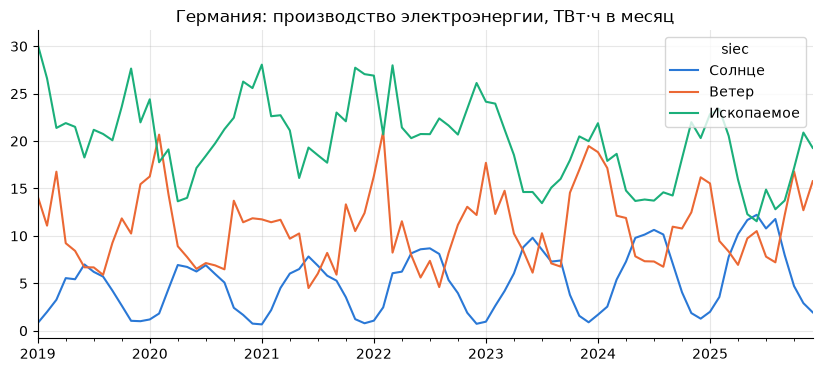

In [12]:
de_mix = mix.loc['DE'] / 1000
de_mix[['RA400', 'RA300', 'CF']].rename(columns={'RA400': 'Солнце', 'RA300': 'Ветер', 'CF': 'Ископаемое'}).plot(
    title='Германия: производство электроэнергии, ТВт·ч в месяц', xlabel='')
plt.show()

**Вывод.** Получено 3024 наблюдения (6 стран × 6 видов топлива × 84 месяца) без пропусков. В Германии на гидро, ветер и солнце в среднем приходится 45% производства, на ископаемое топливо — 49%. Это промежуточное положение между Польшей (80% ископаемого) и Австрией и Данией (66–69% ВИЭ). Сезонность ВИЭ противофазна: ветер даёт максимум зимой (январь ≈ 15,8 ТВт·ч), солнце — летом (июнь ≈ 8,8 ТВт·ч). Ископаемая генерация выше зимой. Это структурное объяснение сезонного паттерна цены.

## 4. Energy-Charts API — JSON

`https://api.energy-charts.info` (Fraunhofer ISE, данные SMARD и ENTSO-E):
- `/price?bzn=DE-LU` — цена на сутки вперёд, EUR/МВт·ч;
- `/public_power?country=de` — генерация по типам, нагрузка, остаточная нагрузка, доля ВИЭ.

Ответ — массив `unix_seconds` и параллельные массивы значений.

In [13]:
EC = 'https://api.energy-charts.info'
t0 = time.perf_counter()
price_parts, power_parts = [], []
for y in YEARS:
    period = {'start': f'{y}-01-01', 'end': f'{y}-12-31'}
    d = json.loads(get(f'{EC}/price', f'energy_charts/price_{y}.json', {'bzn': 'DE-LU', **period}))
    price_parts.append(pd.Series(d['price'], index=pd.to_datetime(d['unix_seconds'], unit='s', utc=True)))

    d = json.loads(get(f'{EC}/public_power', f'energy_charts/power_{y}.json', {'country': 'de', **period}))
    power_parts.append(pd.DataFrame({t['name']: t['data'] for t in d['production_types']},
                                    index=pd.to_datetime(d['unix_seconds'], unit='s', utc=True)))
log_time('4 Energy-Charts', 'загрузка', t0)

t0 = time.perf_counter()
# с 01.10.2025 цена публикуется с шагом 15 минут — приводим всё к часу
price = pd.concat(price_parts).resample('h').mean().rename('price')
power = pd.concat(power_parts).astype(float).resample('h').mean()
log_time('4 Energy-Charts', 'разбор', t0)

print('Типы рядов:', list(power.columns))
power.iloc[:3, :6]

Типы рядов: ['Hydro pumped storage consumption', 'Cross border electricity trading', 'Nuclear', 'Hydro Run-of-River', 'Biomass', 'Fossil brown coal / lignite', 'Fossil hard coal', 'Fossil oil', 'Fossil coal-derived gas', 'Fossil gas', 'Geothermal', 'Hydro water reservoir', 'Hydro pumped storage', 'Others', 'Waste', 'Wind offshore', 'Wind onshore', 'Solar', 'Load', 'Residual load', 'Renewable share of load', 'Renewable share of generation']


,Hydro pumped storage consumption,Cross border electricity trading,Nuclear,Hydro Run-of-River,Biomass,Fossil brown coal / lignite
2018-12-31 23:00:00+00:00,-1273.20,-9677.6,8994.100,1824.225,4787.900,6407.750
2019-01-01 00:00:00+00:00,-1410.45,-10022.0,8528.675,1834.300,4785.775,5441.075
2019-01-01 01:00:00+00:00,-2476.65,-11210.9,7947.500,1753.100,4742.325,5402.275


In [14]:
price.describe().round(1)

count    61368.0
mean        94.7
std         93.8
min       -500.0
25%         37.7
50%         74.0
75%        115.0
max        936.3
Name: price, dtype: float64

In [15]:
year = price.index.tz_convert('Europe/Berlin').year
yearly = pd.DataFrame({'средняя цена': price.groupby(year).mean(),
                       'часов с ценой < 0': (price < 0).groupby(year).sum()})
yearly.round(1)

,средняя цена,часов с ценой < 0
2019,37.7,211
2020,30.5,298
2021,96.8,139
2022,235.4,69
2023,95.2,301
2024,78.5,457
2025,89.3,576


In [16]:
overview(power)

,тип,"пропуски, %",уникальных
Hydro pumped storage consumption,float64,0.00,46462
Cross border electricity trading,float64,0.00,58489
Nuclear,float64,38.76,32366
Hydro Run-of-River,float64,0.00,40121
Biomass,float64,0.00,40243
Fossil brown coal / lignite,float64,0.00,58206
Fossil hard coal,float64,0.00,56800
Fossil oil,float64,0.00,14035
Fossil coal-derived gas,float64,48.61,15125
Fossil gas,float64,0.00,57035


**Вывод.** Ряд цены — 61 368 часов (2019–2025) без пропусков. Цена меняется по режимам: 30–38 EUR/МВт·ч в 2019–2020 гг., 235 в кризисном 2022 г., 78–95 в 2023–2025 гг. Режим рынка нужно учитывать как отдельный признак. Число часов с отрицательной ценой растёт: 211 в 2019 г., 576 в 2025 г. (6,6% часов). Экстремумы: −500 EUR/МВт·ч (02.07.2023, воскресный полдень) и 936 EUR/МВт·ч (12.12.2024, вечер безветренных пасмурных дней). Пропуски в генерации осмысленны. В `Nuclear` их 39%: АЭС закрыты 15.04.2023, после этой даты ряд заполняется нулём. В `Fossil coal-derived gas` — 49%: ряд публикуется не за весь период.

## 5. Open-Meteo Archive API — JSON

Почасовая погода (реанализ ERA5) для пяти крупнейших городов Германии. Ветер на 100 м соответствует высоте ступицы ветрогенератора; `weather_code` — код погоды WMO.

In [17]:
VARS = 'temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m,wind_speed_100m,shortwave_radiation,precipitation,weather_code,is_day'

t0 = time.perf_counter()
frames = []
for city, (lat, lon) in CITIES.items():
    d = json.loads(get('https://archive-api.open-meteo.com/v1/archive', f'open_meteo/{city}.json', {
        'latitude': lat, 'longitude': lon, 'start_date': START, 'end_date': END,
        'hourly': VARS, 'timezone': 'UTC'}))
    frames.append(pd.DataFrame(d['hourly']).assign(city=city))
weather = pd.concat(frames, ignore_index=True)
weather['time'] = pd.to_datetime(weather.time, utc=True)
log_time('5 Open-Meteo', 'загрузка и разбор', t0)

print(weather.shape)
weather.head(3)

(306840, 11)


,time,temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m,wind_speed_100m,shortwave_radiation,precipitation,weather_code,is_day,city
0,2019-01-01 00:00:00+00:00,7.4,98,100,18.9,31.4,0.0,0.0,3,0,Berlin
1,2019-01-01 01:00:00+00:00,7.5,96,100,21.7,34.3,0.0,0.0,3,0,Berlin
2,2019-01-01 02:00:00+00:00,7.2,95,100,23.7,36.7,0.0,0.0,3,0,Berlin


In [18]:
overview(weather)

,тип,"пропуски, %",уникальных
time,"datetime64[us, UTC]",0.0,61368
temperature_2m,float64,0.0,542
relative_humidity_2m,int64,0.0,90
cloud_cover,int64,0.0,101
wind_speed_10m,float64,0.0,472
wind_speed_100m,float64,0.0,738
shortwave_radiation,float64,0.0,916
precipitation,float64,0.0,125
weather_code,int64,0.0,13
is_day,int64,0.0,2


In [19]:
weather.groupby('city')[['temperature_2m', 'wind_speed_100m', 'shortwave_radiation']].mean().round(1)

,temperature_2m,wind_speed_100m,shortwave_radiation
city,,,
Berlin,11.0,22.5,131.9
Cologne,11.8,20.2,132.8
Frankfurt,11.7,18.4,137.8
Hamburg,10.7,23.1,125.0
Munich,10.0,17.7,145.2


## 6. Nager.Date API — JSON (праздники)

В праздники промышленность не работает, и спрос падает так же, как в выходные. Часть праздников отмечается только в отдельных землях (`counties`).

In [20]:
t0 = time.perf_counter()
hol = pd.concat([pd.DataFrame(json.loads(get(f'https://date.nager.at/api/v3/PublicHolidays/{y}/DE', f'nager/{y}.json')))
                 for y in YEARS], ignore_index=True)
hol['date'] = pd.to_datetime(hol.date)
hol['n_states'] = np.where(hol['global'], 16, hol.counties.str.len())  # в скольких землях выходной
log_time('6 Nager.Date', 'загрузка и разбор', t0)

print(hol.shape, '| федеральных:', hol['global'].sum(), '| региональных:', (~hol['global']).sum())
hol[['date', 'localName', 'name', 'global', 'n_states']].head(8)

(135, 10) | федеральных: 63 | региональных: 72


,date,localName,name,global,n_states
0,2019-01-01,Neujahr,New Year's Day,True,16.0
1,2019-01-06,Heilige Drei Könige,Epiphany,False,3.0
2,2019-03-08,Internationaler Frauentag,International Women's Day,False,1.0
3,2019-04-19,Karfreitag,Good Friday,True,16.0
4,2019-04-21,Ostersonntag,Easter Sunday,False,1.0
5,2019-04-22,Ostermontag,Easter Monday,True,16.0
6,2019-05-01,Tag der Arbeit,Labour Day,True,16.0
7,2019-05-30,Christi Himmelfahrt,Ascension Day,True,16.0


## 7. Google News RSS — неструктурированный текст

Выдача ограничена 100 статьями на запрос, поэтому собираем её помесячно (`after:` / `before:`) по трём темам. Здесь изучаем корпус заголовков; аннотирование и векторизация текстов выполняются в п.4.

Альтернатива — GDELT DOC API: даёт тональность, но при проверке отвечал «429 Too Many Requests».

In [21]:
QUERIES = {'strompreis': 'Strompreis Börse', 'negative_preise': '"negative Strompreise"', 'gaspreis': 'Gaspreis Strom'}

t0 = time.perf_counter()
rows = []
for key, query in QUERIES.items():
    for month in pd.date_range(START, END, freq='MS'):
        next_month = month + pd.offsets.MonthBegin()
        params = {'q': f'{query} after:{month:%Y-%m-%d} before:{next_month:%Y-%m-%d}',
                  'hl': 'de', 'gl': 'DE', 'ceid': 'DE:de'}
        rss = get('https://news.google.com/rss/search', f'news/{key}/{month:%Y-%m}.xml', params)
        for item in ET.fromstring(rss).iter('item'):
            rows.append({'query': key, 'title': item.findtext('title'), 'source': item.findtext('source'),
                         'pub_date': item.findtext('pubDate')})
news = pd.DataFrame(rows)
log_time('7 News', 'загрузка и разбор', t0)

news['pub_date'] = pd.to_datetime(news.pub_date, format='%a, %d %b %Y %H:%M:%S GMT', utc=True)
news['title'] = news.title.str.rsplit(' - ', n=1).str[0]  # убираем « - Издание» в конце заголовка
news = news.drop_duplicates(['title', 'source'])
news['n_words'] = news.title.str.split().str.len()

print(news.shape)
news.sample(5, random_state=1)

(2625, 5)


,query,title,source,pub_date,n_words
2266,gaspreis,Stadtwerke Bochum wollen fremden Zähler tausch...,WAZ | Westdeutsche Allgemeine Zeitung,2024-09-28 07:00:00+00:00,8
714,gaspreis,Wie ein Herforder Buchhändler den Klimaschutz ...,Neue Westfälische,2019-10-04 07:00:00+00:00,10
722,gaspreis,Neues Heizkraftwerk Lichterfelde startet in de...,Vattenfall,2019-11-30 08:00:00+00:00,7
1031,gaspreis,Gasalarm in Geretsried: Evakuierung aufgehoben...,Merkur,2021-06-11 07:00:00+00:00,8
770,gaspreis,Der Markt wartet auf die neuen Strategien von ...,Handelsblatt,2020-01-07 08:00:00+00:00,11


In [22]:
print(news['query'].value_counts(), '\n')
print(news.source.value_counts().head(10))

query
gaspreis           2082
strompreis          361
negative_preise     182
Name: count, dtype: int64 

source
Merkur                                    129
Handelsblatt                              116
ZFK – Zeitung für kommunale Wirtschaft     98
agrarheute.com                             87
Spiegel                                    61
Frankfurter Rundschau                      60
RND.de                                     60
FOCUS online                               59
RP Online                                  44
FAZ                                        43
Name: count, dtype: int64


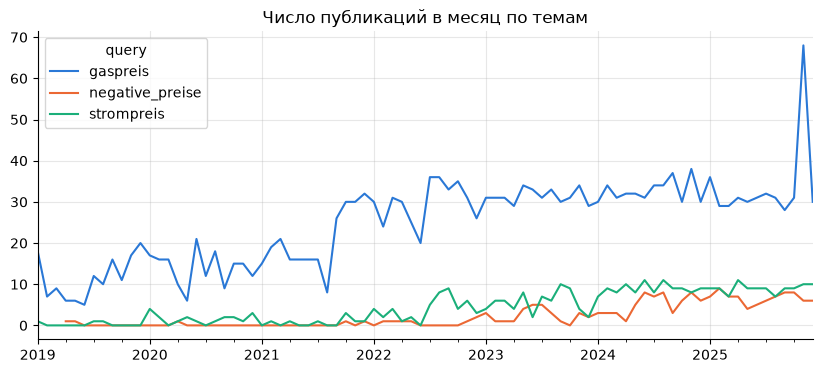

In [23]:
news.set_index('pub_date').groupby('query').resample('MS').size().unstack(0).plot(
    title='Число публикаций в месяц по темам', xlabel='')
plt.show()

**Вывод.** Собрано 2625 уникальных заголовков. Узкие запросы дают релевантные тексты. Запрос «negative Strompreise» вырос с 2 публикаций в 2019 г. до 80 в 2025 г. — синхронно с ростом числа часов с отрицательной ценой. Запрос «Gaspreis Strom» шумный: только около половины заголовков содержат слова о ценах на газ или электроэнергию. В п.4 нужна фильтрация по релевантности. Рост числа публикаций к 2025 г. отчасти вызван тем, что поисковик лучше индексирует свежие новости, поэтому корректнее использовать доли тем, а не абсолютные счётчики.

## 8. Сводка по источникам

Требование п.3: в каждом наборе не меньше 3 категориальных и 3 числовых характеристик.

| Источник | Категориальные | Числовые | Время |
|:--|:--|:--|:--|
| 1 OPSD | регион (DE, DE_LU, 4 зоны операторов сетей), переменная, атрибут | цена, нагрузка, генерация солнца и ветра, установленная мощность | час |
| 2 ENTSO-E | зона, тип документа / бизнес-тип, тип генерации (psrType), шаг | цена, нагрузка, генерация по типам | 15 мин / час |
| 3 Eurostat | страна, вид топлива (siec), единица, частота | производство всего, ископаемое, ветер, солнце, атом, доля ВИЭ | месяц |
| 4 Energy-Charts | зона, тип генерации (19 типов), вид показателя | цена, нагрузка, остаточная нагрузка, генерация, доля ВИЭ | 15 мин / час |
| 5 Open-Meteo | город, код погоды WMO, день/ночь | температура, влажность, облачность, ветер 10 и 100 м, радиация, осадки | час |
| 6 Nager.Date | название, уровень (федеральный / региональный), земли, тип | число земель с выходным (остальные числовые признаки производные) | день |
| 7 News | тема запроса, издание, язык | длина заголовка, число публикаций в день, тональность (п.4) | дата публикации |

In [24]:
pd.DataFrame({
    'строк': [len(opsd), len(eurostat), len(price), len(weather), len(hol), len(news)],
    'столбцов': [opsd.shape[1], eurostat.shape[1], power.shape[1] + 1, weather.shape[1], hol.shape[1], news.shape[1]],
}, index=['1 OPSD', '3 Eurostat', '4 Energy-Charts', '5 Open-Meteo', '6 Nager.Date', '7 News'])

,строк,столбцов
1 OPSD,50401,42
3 Eurostat,3024,6
4 Energy-Charts,61368,23
5 Open-Meteo,306840,11
6 Nager.Date,135,10
7 News,2625,5


## 9. Первичные наблюдения

Предварительно объединяем данные по часу: цена и генерация, погода (среднее по пяти городам), праздники. Полное слияние — в п.4–5.

In [25]:
t0 = time.perf_counter()
weather_mean = weather.groupby('time')[['temperature_2m', 'wind_speed_100m', 'shortwave_radiation', 'cloud_cover']].mean()
df = pd.concat([price, power[['Load', 'Residual load', 'Solar', 'Wind onshore', 'Wind offshore',
                              'Fossil gas', 'Renewable share of load']], weather_mean], axis=1).loc[START:END]

local = df.index.tz_convert('Europe/Berlin')
df['hour'] = local.hour
df['month'] = local.month
df['year'] = local.year
df['date'] = local.date
df['regime'] = pd.cut(df.year, [2018, 2020, 2022, 2025], labels=['2019–20', '2021–22 (кризис)', '2023–25'])
federal_holidays = set(hol.loc[hol['global'], 'date'].dt.date)
df['day_type'] = np.where(df.date.isin(federal_holidays), 'праздник',
                 np.where(local.dayofweek >= 5, 'выходной', 'рабочий'))
# «дешёвое окно» — час из 25% самых дешёвых часов своих суток
df['is_cheap_window'] = df.price <= df.groupby('date').price.transform('quantile', 0.25)
df['price_rank_in_day'] = df.groupby('date').price.rank(method='first')
log_time('слияние', 'предварительное', t0)

print(df.shape)
df.head(3)

(61368, 20)


,price,Load,Residual load,Solar,Wind onshore,Wind offshore,Fossil gas,Renewable share of load,temperature_2m,wind_speed_100m,shortwave_radiation,cloud_cover,hour,month,year,date,regime,day_type,is_cheap_window,price_rank_in_day
2019-01-01 00:00:00+00:00,10.07,41631.475,16592.100,0.0,22171.700,2867.675,3057.475,77.750,6.46,25.78,0.0,97.0,1,1,2019,2019-01-01,2019–20,праздник,False,23.0
2019-01-01 01:00:00+00:00,-4.08,40084.725,14587.075,0.0,23037.700,2459.925,2803.100,81.600,6.32,27.68,0.0,98.8,2,1,2019,2019-01-01,2019–20,праздник,False,14.0
2019-01-01 02:00:00+00:00,-9.91,39269.825,12239.875,0.0,24333.825,2696.125,2733.800,87.075,6.08,29.68,0.0,97.4,3,1,2019,2019-01-01,2019–20,праздник,True,6.0


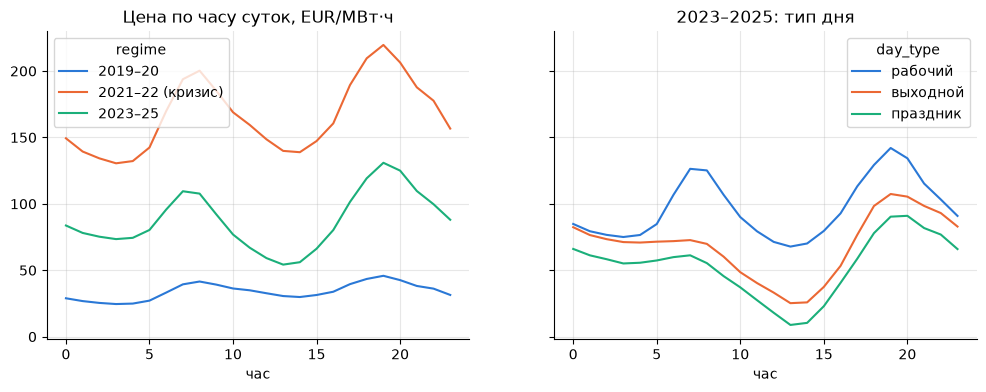

In [26]:
recent = df[df.year >= 2023]  # после энергокризиса 2021–2022
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
df.groupby(['regime', 'hour'], observed=True).price.mean().unstack(0).plot(
    ax=ax1, title='Цена по часу суток, EUR/МВт·ч', xlabel='час')
recent.groupby(['day_type', 'hour']).price.mean().unstack(0)[['рабочий', 'выходной', 'праздник']].plot(
    ax=ax2, title='2023–2025: тип дня', xlabel='час')
plt.show()

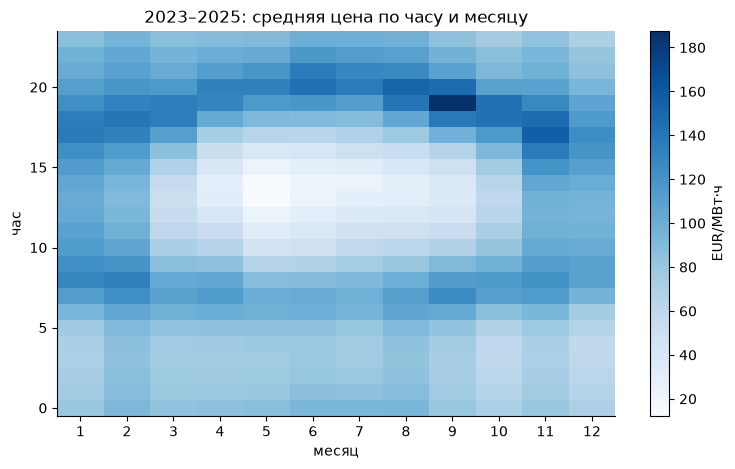

In [27]:
heat = recent.pivot_table(index='hour', columns='month', values='price')
plt.figure(figsize=(9, 5))
plt.imshow(heat, aspect='auto', origin='lower', cmap='Blues')
plt.colorbar(label='EUR/МВт·ч')
plt.xticks(range(12), range(1, 13)); plt.xlabel('месяц'); plt.ylabel('час')
plt.title('2023–2025: средняя цена по часу и месяцу'); plt.grid(False)
plt.show()

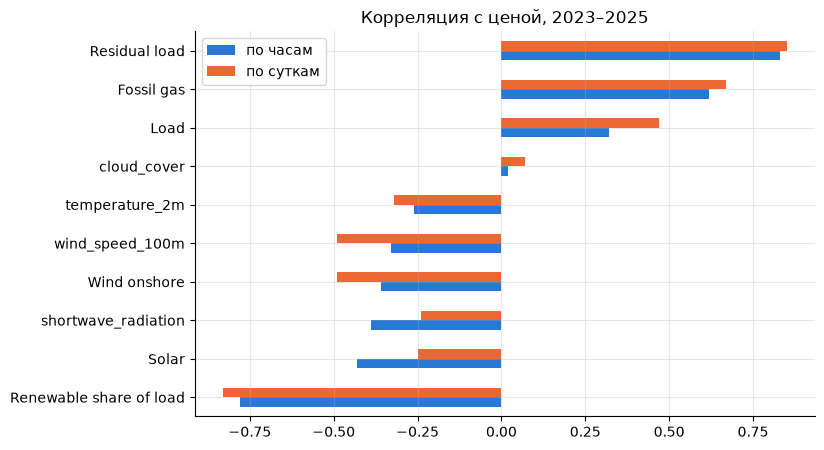

,по часам,по суткам
Renewable share of load,-0.78,-0.83
Solar,-0.43,-0.25
shortwave_radiation,-0.39,-0.24
Wind onshore,-0.36,-0.49
wind_speed_100m,-0.33,-0.49
temperature_2m,-0.26,-0.32
cloud_cover,0.02,0.07
Load,0.32,0.47
Fossil gas,0.62,0.67
Residual load,0.83,0.85


In [28]:
factors = ['wind_speed_100m', 'shortwave_radiation', 'temperature_2m', 'cloud_cover',
           'Load', 'Residual load', 'Solar', 'Wind onshore', 'Fossil gas', 'Renewable share of load']
corr = pd.DataFrame({
    'по часам': recent[factors].corrwith(recent.price),
    'по суткам': recent.groupby('date')[factors + ['price']].mean().corr()['price'][factors],
}).round(2).sort_values('по часам')
corr.plot.barh(title='Корреляция с ценой, 2023–2025', figsize=(8, 5))
plt.show()
corr

In [29]:
# доля часов, попадающих в «дешёвые окна», по часу суток, %
recent.pivot_table(index='day_type', columns='hour', values='is_cheap_window').mul(100).round()

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
выходной,7.0,14.0,17.0,28.0,29.0,22.0,21.0,8.0,1.0,3.0,...,72.0,64.0,37.0,4.0,1.0,2.0,5.0,5.0,6.0,16.0
праздник,4.0,11.0,26.0,30.0,37.0,37.0,30.0,11.0,7.0,4.0,...,67.0,59.0,37.0,4.0,0.0,0.0,0.0,0.0,4.0,11.0
рабочий,27.0,42.0,48.0,52.0,48.0,28.0,1.0,0.0,0.0,1.0,...,60.0,51.0,30.0,3.0,0.0,0.0,2.0,5.0,8.0,22.0


**Вывод.** - **Час суток** (2023–2025): минимум цены в 13:00 (54 EUR/МВт·ч), максимум в 19:00 (131 EUR/МВт·ч), то есть в 2,4 раза выше. В 2019–2020 гг. полуденного провала почти не было: он появился с ростом солнечной генерации.
- **Тип дня**: в будни в среднем 91–99, в субботу 74, в воскресенье 63 EUR/МВт·ч. Профиль праздников близок к воскресному.
- **Сезон**: самые дорогие месяцы — январь, февраль и ноябрь (102–106), самый дешёвый — май (72).
- **Погода**: ветер на 100 м даёт корреляцию с ценой −0,33 по часам и −0,49 по суткам, температура −0,26 / −0,32, солнечная радиация −0,39 по часам. Облачность сама по себе почти не связана с ценой.
- **Сильнейшие факторы**: остаточная нагрузка (+0,83), доля ВИЭ в нагрузке (−0,78) и газовая генерация (+0,62). Это фактические значения, которые неизвестны заранее. Для прогноза их нужно заменить прогнозами нагрузки и выработки ВИЭ (ENTSO-E) или погодными признаками.
- **«Дешёвые окна»** в будни приходятся на ночь (02–04 ч, около 50% дней) и полдень (12–15 ч, около 60%). В выходные и праздники они смещаются на полдень (14 ч — 67–72%). Вечером с 17 до 21 ч дешёвых окон почти нет.

Предварительно гипотеза подтверждается: время суток, тип дня, ветер и температура связаны с ценой. В список факторов нужно добавить солнечную радиацию и признаки баланса спроса и ВИЭ.

## 10. Аналитический портрет

**Состояние объекта (целевые показатели)**

| Характеристика | Источник | Тип, шкала | Роль |
|:--|:--|:--|:--|
| `price` — цена за час | Energy-Charts, ENTSO-E, OPSD | числовой, отношений (бывает < 0) | целевая для прогноза |
| `is_cheap_window` — час в 25% самых дешёвых часов суток | из цены | категориальный, бинарный | целевая для классификации |
| `price_rank_in_day` — ранг часа по цене за сутки | из цены | категориальный, порядковый | планирование задач |
| `Load`, `Residual load` — нагрузка и нагрузка за вычетом ветра и солнца | Energy-Charts, ENTSO-E | числовой, отношений | состояние спроса и баланса |
| `bidding_zone` — ценовая зона | рыночные источники | категориальный, номинальный | ключ слияния |

**Факторы влияния**

| Группа | Характеристики | Источник | Тип, шкала |
|:--|:--|:--|:--|
| Погода | `wind_speed_100m`, `shortwave_radiation`, `temperature_2m`, `cloud_cover` | Open-Meteo | числовые; температура — интервальная, остальные — отношений |
| Погода | `weather_code`, `is_day` | Open-Meteo | категориальные, номинальные |
| Генерация | `Solar`, `Wind onshore/offshore`, `Fossil gas`, `Renewable share of load` | Energy-Charts, ENTSO-E | числовые, отношений |
| Генерация | `production_type`; доли ВИЭ и ископаемого топлива по месяцам и странам | Energy-Charts, Eurostat | категориальный / числовые |
| Календарь | `hour`, `day_of_week`, `month` | время | категориальные, порядковые (циклические) |
| Поведение | `day_type` (рабочий / выходной / праздник), `n_states` | Nager.Date | категориальный / числовой |
| Новости | число публикаций по теме, тональность, тема | Google News | числовые / категориальные |
| Режим рынка | до кризиса / кризис 2021–22 / после | из даты | категориальный, порядковый |

**Ключи слияния:** час UTC (почасовые ряды), дата по Europe/Berlin (праздники, новости), месяц (Eurostat), ценовая зона.

## 11. Время обработки

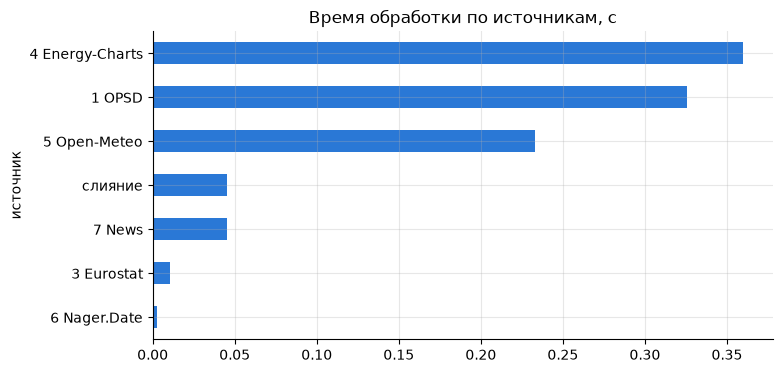

,источник,этап,секунд
0,1 OPSD,загрузка,0.053
1,1 OPSD,SQL-агрегация,0.017
2,1 OPSD,чтение,0.256
3,3 Eurostat,загрузка,0.000
4,3 Eurostat,разбор,0.010
5,4 Energy-Charts,загрузка,0.340
6,4 Energy-Charts,разбор,0.020
7,5 Open-Meteo,загрузка и разбор,0.233
8,6 Nager.Date,загрузка и разбор,0.003
9,7 News,загрузка и разбор,0.045


In [30]:
t = pd.DataFrame(timings)
t.groupby('источник').секунд.sum().sort_values().plot.barh(title='Время обработки по источникам, с', figsize=(8, 4))
plt.show()
t.round(3)

При повторном запуске данные берутся из `data/raw`, поэтому «загрузка» — это время чтения с диска; первый запуск дольше (основное — OPSD 226 МБ и ~250 запросов новостей).

## Итог

1. Требования п.3 выполнены. Реляционный набор — OPSD (SQLite). XML — Eurostat SDMX, а также ENTSO-E: парсер готов, для реальной выгрузки нужен токен. JSON API — Energy-Charts, Open-Meteo, Nager.Date. Текст — Google News. В каждом наборе не меньше 3 категориальных и 3 числовых характеристик (у Nager.Date часть числовых — производные), у всех есть время.
2. Источники покрывают и предмет исследования (цена и спрос — Energy-Charts, ENTSO-E, OPSD), и факторы: погода, структура генерации, календарь и праздники, новостной фон.
3. Аналитический портрет (раздел 10): целевые показатели `price` и `is_cheap_window`, состояние спроса `Load` и `Residual load`, факторы — погода, генерация, час, тип дня, сезон, праздники, новости, режим рынка. Общие ключи: час UTC, местная дата, месяц, ценовая зона.
4. Для п.4 нужно: заполнить пропуски `Nuclear` и `coal-derived gas`, отфильтровать нерелевантные новости, учесть смену режима рынка и 15-минутный шаг с 10.2025, а для прогноза заменить фактическую нагрузку и генерацию их прогнозами.